# 01. Dữ liệu phụ tải GEFCom2012: đọc, ghép, chuyển dạng và làm sạch

**Đồ án:** Ứng dụng Tree of Thoughts / Graph of Thoughts trong dự báo phụ tải điện
**Giai đoạn 2, notebook 1/3.** Tương ứng các mục 2.1–2.6 trong checklist.

## Mục tiêu của notebook

Đi từ file CSV gốc của cuộc thi đến **một chuỗi phụ tải theo giờ sạch, liên tục, không thiếu giá trị**, lưu ra file parquet để các notebook sau dùng lại. Cụ thể:

| Mục | Nội dung |
|---|---|
| 2.2 | Đọc `Load_history.csv`, hiểu cấu trúc bảng rộng |
| 2.3 | Tìm những ngày bị xóa trống |
| 2.4 | Khám phá `Load_solution.csv` và ghép vào để lấp chỗ trống |
| 2.5 | Chuyển sang bảng dài (mỗi dòng một giờ), gắn nhãn thời gian |
| 2.6 | Lấp 18 giờ còn thiếu, tạo chuỗi tổng hệ thống, lưu parquet |

## Cách trình bày

Mỗi phần gồm bốn bước: **Lý thuyết → Mục đích → Việc cần làm → Code**. Trong code, chú thích `# [M1]`, `# [M2]`… chỉ ra dòng đó phục vụ mục đích nào đã nêu. Sau mỗi phần có **kiểm tra** bằng `assert` (sai thì notebook dừng ngay) và **nhận xét kết quả**.

## Bối cảnh dữ liệu

GEFCom2012 (Global Energy Forecasting Competition 2012), track Load, do IEEE Working Group on Energy Forecasting tổ chức trên Kaggle. Dữ liệu là phụ tải điện theo giờ của **20 zone** thuộc một công ty điện ở Mỹ (ẩn danh), từ 01/01/2004 đến 07/07/2008, kèm nhiệt độ của 11 trạm và danh sách ngày lễ. Nhiệt độ và ngày lễ được xử lý ở notebook 02.

## 0. Chuẩn bị môi trường

Kiểm tra notebook đang chạy đúng môi trường conda của đồ án và in phiên bản thư viện. Ghi lại phiên bản giúp tái lập kết quả: cùng code nhưng khác phiên bản pandas đôi khi cho kết quả khác.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python      :", sys.executable)   # phải trỏ vào env của đồ án
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)

# Đường dẫn tương đối tính từ thư mục notebooks/
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Danh sách 24 cột giờ và 4 cột khóa, dùng xuyên suốt notebook
HOUR_COLS = [f"h{i}" for i in range(1, 25)]       # ["h1", "h2", ..., "h24"]
KEYS = ["zone_id", "year", "month", "day"]       # một dòng = một zone trong một ngày

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

Python      : D:\Dev_Env\Dev_Env_Tools\anaconda3\envs\opt_ai\python.exe
pandas      : 2.3.3
numpy       : 2.2.6


## 1. Đọc `Load_history.csv` (mục 2.2)

### Lý thuyết

File phụ tải ở dạng **bảng rộng** (wide format): mỗi dòng là **một zone trong một ngày**, 24 giờ trải ngang trên 24 cột `h1`…`h24`.

Khi mở file bằng Notepad, các số phụ tải được ghi kiểu Mỹ, có **dấu phẩy phân cách hàng nghìn** và được bọc trong ngoặc kép: `"16,853"` nghĩa là 16 853. Vì CSV dùng dấu phẩy để ngăn cột, số có dấu phẩy phải nằm trong ngoặc kép. Nếu đọc thẳng, pandas sẽ coi các cột này là **chuỗi ký tự** (`object`) thay vì số. Tham số `thousands=","` của `pd.read_csv` báo cho pandas bỏ dấu phẩy hàng nghìn khi đọc.

### Mục đích

- **[M1]** Đọc dữ liệu thành **số**, không phải chuỗi.
- **[M2]** Đối chiếu kích thước bảng với hiểu biết về dữ liệu, để phát hiện sớm lỗi đọc file.

### Việc cần làm

1. Đọc file với `thousands=","`.
2. Kiểm tra kiểu dữ liệu của 24 cột giờ.
3. Kiểm tra số dòng: 20 zone × số ngày từ 01/01/2004 đến 07/07/2008.

In [2]:
# [M1] Đọc file, bỏ dấu phẩy hàng nghìn
load = pd.read_csv(RAW_DIR / "Load_history.csv", thousands=",")

print("Kích thước:", load.shape)
print("Kiểu dữ liệu của các cột giờ:", load[HOUR_COLS].dtypes.unique())
load.head()

Kích thước: (33000, 28)
Kiểu dữ liệu của các cột giờ: [dtype('float64')]


,zone_id,year,month,day,h1,h2,h3,h4,h5,h6,...,h15,h16,h17,h18,h19,h20,h21,h22,h23,h24
0,1,2004,1,1,16853.0,16450.0,16517.0,16873.0,17064.0,17727.0,...,13518.0,13138.0,14130.0,16809.0,18150.0,18235.0,17925.0,16904.0,16162.0,14750.0
1,1,2004,1,2,14155.0,14038.0,14019.0,14489.0,14920.0,16072.0,...,16127.0,15448.0,15839.0,17727.0,18895.0,18650.0,18443.0,17580.0,16467.0,15258.0
2,1,2004,1,3,14439.0,14272.0,14109.0,14081.0,14775.0,15491.0,...,13507.0,13414.0,13826.0,15825.0,16996.0,16394.0,15406.0,14278.0,13315.0,12424.0
3,1,2004,1,4,11273.0,10415.0,9943.0,9859.0,9881.0,10248.0,...,14207.0,13614.0,14162.0,16237.0,17430.0,17218.0,16633.0,15238.0,13580.0,11727.0
4,1,2004,1,5,10750.0,10321.0,10107.0,10065.0,10419.0,12101.0,...,13845.0,14350.0,15501.0,17307.0,18786.0,19089.0,19192.0,18416.0,17006.0,16018.0


In [3]:
# [M2] Đối chiếu số dòng với hiểu biết về dữ liệu
n_days = (pd.Timestamp("2008-07-07") - pd.Timestamp("2004-01-01")).days + 1   # tính cả hai đầu
print("Số ngày từ 01/01/2004 đến 07/07/2008:", n_days)
print("20 zone x số ngày =", 20 * n_days)

assert load.shape == (20 * n_days, 28), "Số dòng / số cột không khớp với kỳ vọng"
assert load["zone_id"].nunique() == 20

Số ngày từ 01/01/2004 đến 07/07/2008: 1650
20 zone x số ngày = 33000


### Nhận xét

- Bảng có **33 000 dòng × 28 cột** = 20 zone × 1 650 ngày, gồm 4 cột khóa (`zone_id, year, month, day`) và 24 cột giờ.
- Các cột giờ có kiểu **`float64`**, không phải `int64`, dù phụ tải là số nguyên. Lý do: trong bảng có ô trống. Ô trống được pandas biểu diễn bằng `NaN`, mà theo chuẩn IEEE 754 `NaN` là một giá trị **thuộc kiểu số thực**. Kiểu `int64` không có chỗ cho giá trị thiếu, nên pandas tự nâng kiểu cả cột lên `float64`.

## 2. Tìm những ngày bị xóa trống (mục 2.3)

### Lý thuyết

Đây là dữ liệu của một **cuộc thi**. Ban tổ chức đã cố ý xóa trống một số giai đoạn để làm đề bài:

- **8 tuần rải rác** trong lịch sử: người dự thi phải điền lại (*backcasting*).
- **Tuần cuối cùng** (01/07–07/07/2008): người dự thi phải dự báo (*forecasting*).

Giá trị thật của các tuần này được công bố sau cuộc thi trong file `Load_solution.csv`.

### Mục đích

- **[M1]** Xác định chính xác **những ngày nào** bị trống, để biết cần lấy gì từ file solution.
- **[M2]** Phát hiện các trường hợp **trống một phần** (một ngày chỉ thiếu vài giờ), vì cách xử lý sẽ khác.

### Việc cần làm

1. Với mỗi dòng, đánh dấu: có **ít nhất một** giờ trống, và **cả 24** giờ đều trống.
2. Nếu hai con số khác nhau, tìm các dòng trống một phần.
3. Liệt kê các ngày trống toàn bộ và gom thành các tuần.

In [4]:
na = load[HOUR_COLS].isna()          # bảng True/False cùng kích thước: True = ô trống
any_na = na.any(axis=1)              # axis=1: gộp theo HÀNG -> dòng có ít nhất 1 ô trống
all_na = na.all(axis=1)              # dòng trống cả 24 ô

print("Dòng có ít nhất một giờ trống :", any_na.sum())
print("Dòng trống toàn bộ 24 giờ     :", all_na.sum())

Dòng có ít nhất một giờ trống : 1280
Dòng trống toàn bộ 24 giờ     : 1260


In [5]:
# [M2] Các dòng trống MỘT PHẦN: có trống nhưng không trống hết (~ là phép phủ định)
partial = load[any_na & ~all_na]
print("Các ngày trống một phần:")
print(partial[["year", "month", "day"]].drop_duplicates().to_string(index=False))

# Xem cụ thể một dòng: giờ nào có số, giờ nào trống
print("\nZone 1, ngày đó, giờ nào trống (1 = trống):")
print(partial.iloc[0][HOUR_COLS].isna().astype(int).to_dict())

Các ngày trống một phần:
 year  month  day
 2008      6   30

Zone 1, ngày đó, giờ nào trống (1 = trống):
{'h1': 0, 'h2': 0, 'h3': 0, 'h4': 0, 'h5': 0, 'h6': 0, 'h7': 1, 'h8': 1, 'h9': 1, 'h10': 1, 'h11': 1, 'h12': 1, 'h13': 1, 'h14': 1, 'h15': 1, 'h16': 1, 'h17': 1, 'h18': 1, 'h19': 1, 'h20': 1, 'h21': 1, 'h22': 1, 'h23': 1, 'h24': 1}


In [6]:
# [M1] Liệt kê các ngày trống toàn bộ
missing = load[all_na].copy()                                    # .copy() để tránh cảnh báo khi thêm cột
missing["date"] = pd.to_datetime(missing[["year", "month", "day"]])
missing_dates = missing["date"].drop_duplicates().sort_values()

print("Số ngày trống toàn bộ:", len(missing_dates))
print("Mỗi ngày trống ở bao nhiêu zone:", missing.groupby("date")["zone_id"].nunique().unique())

# Gom các ngày liên tiếp thành từng "đợt": chỗ nào cách ngày trước hơn 1 ngày là bắt đầu đợt mới
gap = missing_dates.diff().dt.days.ne(1)          # True ở ngày đầu mỗi đợt
week_id = gap.cumsum()                            # đánh số đợt 1, 2, 3, ...
weeks = (missing_dates.groupby(week_id.values)
         .agg(["min", "max", "count"])
         .rename(columns={"min": "từ ngày", "max": "đến ngày", "count": "số ngày"}))
weeks["thứ bắt đầu"] = weeks["từ ngày"].dt.day_name()
weeks

Số ngày trống toàn bộ: 63
Mỗi ngày trống ở bao nhiêu zone: [20]


,từ ngày,đến ngày,số ngày,thứ bắt đầu
1,2005-03-06,2005-03-12,7,Sunday
2,2005-06-20,2005-06-26,7,Monday
3,2005-09-10,2005-09-16,7,Saturday
4,2005-12-25,2005-12-31,7,Sunday
5,2006-02-13,2006-02-19,7,Monday
6,2006-05-25,2006-05-31,7,Thursday
7,2006-08-02,2006-08-08,7,Wednesday
8,2006-11-22,2006-11-28,7,Wednesday
9,2008-07-01,2008-07-07,7,Tuesday


In [7]:
assert any_na.sum() == 1280 and all_na.sum() == 1260
assert len(missing_dates) == 63 and len(weeks) == 9 and (weeks["số ngày"] == 7).all()

### Nhận xét

- Có **63 ngày** trống toàn bộ, ở **cả 20 zone** (63 × 20 = 1 260 dòng), gom thành **9 tuần**, mỗi tuần đủ 7 ngày:
  - 8 tuần backcast nằm rải rác trong 2005–2006, bắt đầu vào các thứ khác nhau.
  - 1 tuần dự báo: 01/07–07/07/2008.
- Có thêm **20 dòng trống một phần**: ngày **30/06/2008** của cả 20 zone, chỉ có số liệu `h1`–`h6`, còn `h7`–`h24` trống. Điều này khớp với mô tả cuộc thi: dữ liệu huấn luyện kết thúc lúc **06:00 ngày 30/06/2008**.

## 3. Khám phá `Load_solution.csv` (mục 2.4, phần 1)

### Lý thuyết

Trước khi ghép, phải hiểu file solution **khác gì** `Load_history`. Quy trình chung cho mọi bước khám phá dữ liệu trong đồ án: **quan sát → đặt giả thuyết → kiểm tra bằng code trên toàn bộ dữ liệu**. Không kết luận từ vài dòng nhìn bằng mắt.

### Mục đích

- **[M1]** Xác nhận file chứa đúng 63 ngày bị xóa.
- **[M2]** Hiểu các cột và zone **mới** so với `Load_history`, để quyết định giữ hay bỏ.

### Việc cần làm

| Kiểm chứng | Câu hỏi | Cách kiểm tra |
|---|---|---|
| 1 | File chứa những gì? | So kích thước với 63 ngày × số zone |
| 2 | Zone 21 là gì? | Giả thuyết: tổng 20 zone. So từng giờ |
| 3 | Cột `weight` là gì? | Đếm giá trị theo loại zone và loại tuần |
| 4 | Cột `id` là gì? | Kiểm tra có phải số thứ tự 1..n |

In [8]:
sol = pd.read_csv(RAW_DIR / "Load_solution.csv", thousands=",")

# Kiểm chứng 1 [M1]: kích thước và các cột mới
print("Kích thước:", sol.shape)
print("Số zone:", sol["zone_id"].nunique(), "->", sorted(sol["zone_id"].unique().tolist()))
print("Cột có trong solution nhưng không có trong history:", set(sol.columns) - set(load.columns))
assert sol.shape[0] == 63 * 21

Kích thước: (1323, 30)
Số zone: 21 -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Cột có trong solution nhưng không có trong history: {'id', 'weight'}


In [9]:
# Kiểm chứng 2 [M2]: zone 21 có bằng tổng zone 1..20 không?

# (a) Thử bằng tay cho 1 ngày, 1 giờ
one_day = sol[(sol["year"] == 2005) & (sol["month"] == 3) & (sol["day"] == 6)]
print("Tổng h1 của zone 1..20 :", one_day.loc[one_day["zone_id"] <= 20, "h1"].sum())
print("h1 của zone 21          :", one_day.loc[one_day["zone_id"] == 21, "h1"].iloc[0])

# (b) Mở rộng cho toàn bộ 63 ngày x 24 giờ
zones_sum = (sol[sol["zone_id"] <= 20]
             .groupby(["year", "month", "day"])[HOUR_COLS]
             .sum())                                   # 63 dòng x 24 cột: tổng 20 zone mỗi giờ
system_21 = (sol[sol["zone_id"] == 21]
             .set_index(["year", "month", "day"])[HOUR_COLS])   # cùng chỉ mục để trừ khớp từng ngày

max_diff = (zones_sum - system_21).abs().max().max()  # pandas trừ theo CHỈ MỤC, không theo thứ tự dòng
print("Chênh lệch lớn nhất trên 63 x 24 ô:", max_diff)
assert max_diff == 0

Tổng h1 của zone 1..20 : 1719688
h1 của zone 21          : 1719688
Chênh lệch lớn nhất trên 63 x 24 ô: 0


In [10]:
# Kiểm chứng 3 [M2]: weight phụ thuộc vào gì?
is_system = sol["zone_id"] == 21                  # zone tổng hệ thống?
is_forecast_week = sol["year"] == 2008            # tuần dự báo là tuần duy nhất rơi vào 2008
pd.crosstab([is_system.rename("zone hệ thống"), is_forecast_week.rename("tuần dự báo")],
            sol["weight"])

weight                      1    8    20   160
zone hệ thống tuần dự báo                     
False         False        1120    0    0    0
              True            0  140    0    0
True          False           0    0   56    0
              True            0    0    0    7

In [11]:
# Kiểm chứng 4 [M2]: id có phải số thứ tự?
print("id không lặp:", sol["id"].is_unique, "| min:", sol["id"].min(), "| max:", sol["id"].max())
assert sol["id"].is_unique and sol["id"].min() == 1 and sol["id"].max() == len(sol)

id không lặp: True | min: 1 | max: 1323


### Nhận xét

| # | Câu hỏi | Kết luận | Xử lý |
|---|---|---|---|
| 1 | File chứa gì? | 1 323 dòng = 63 ngày bị xóa × 21 zone; thêm hai cột `id`, `weight` | Dùng để lấp chỗ trống |
| 2 | Zone 21 là gì? | **Tổng phụ tải toàn hệ thống**, bằng chính xác tổng zone 1–20 (chênh lệch lớn nhất = 0) | Bỏ khi ghép; tự tính lại cho toàn bộ chuỗi ở mục 6 |
| 3 | `weight` là gì? | Trọng số chấm điểm của cuộc thi: zone thường 1 (backcast) / 8 (dự báo); hệ thống 20 / 160. Hai hệ số nhân nhau: 20 × 8 = 160 | Bỏ, vì đồ án dùng giao thức đánh giá riêng |
| 4 | `id` là gì? | Số thứ tự dòng 1…1 323, dùng để nộp bài | Bỏ |

**Lưu ý:** file solution **không có** ngày 30/06/2008, nên 18 giờ `h7`–`h24` của ngày này vẫn sẽ thiếu sau khi ghép.

## 4. Ghép solution vào history (mục 2.4, phần 2)

### Lý thuyết

Với mỗi ô trống trong `load`, ta tìm ô **cùng zone, cùng ngày, cùng giờ** trong `sol` để điền vào. "Cùng zone, cùng ngày" nghĩa là khớp theo 4 cột `zone_id, year, month, day`, nên ta dùng 4 cột này làm **chỉ mục** (index) cho cả hai bảng. Khi đó `DataFrame.fillna(other)` sẽ điền mỗi ô `NaN` bằng ô có **cùng chỉ mục và cùng tên cột** trong `other`. Ô đã có giá trị thì giữ nguyên.

### Mục đích

- **[M1]** Lấp toàn bộ 63 ngày bị xóa bằng giá trị thật.
- **[M2]** Đảm bảo **không điền sai chỗ** và **không ghi đè** dữ liệu gốc.

### Việc cần làm

1. Làm sạch `sol`: chỉ giữ zone 1–20, bỏ `id` và `weight`, để có đúng 28 cột như `load`.
2. Đặt chỉ mục 4 cột cho cả hai bảng, rồi `fillna`.
3. Kiểm tra hai điều: ô vừa điền **bằng đúng** giá trị trong `sol`; ô vốn có giá trị **không bị thay đổi**.

In [12]:
# Bước 1: làm sạch solution
sol_clean = sol[sol["zone_id"] <= 20].drop(columns=["id", "weight"])
assert list(sol_clean.columns) == list(load.columns)          # đúng 28 cột, đúng thứ tự
print("sol_clean:", sol_clean.shape)                          # kỳ vọng (1260, 28)

# Bước 2 [M1]: ghép theo chỉ mục 4 cột
load_idx = load.set_index(KEYS)
sol_idx = sol_clean.set_index(KEYS)
full = load_idx.fillna(sol_idx)

print("full:", full.shape)
print("Dòng còn ô trống:", full.isna().any(axis=1).sum(), "| dòng trống toàn bộ:", full.isna().all(axis=1).sum())

sol_clean: (1260, 28)
full: (33000, 24)
Dòng còn ô trống: 20 | dòng trống toàn bộ: 0


In [13]:
# Bước 3 [M2]: hai kiểm tra an toàn
# (a) Các ô vừa điền có đúng bằng giá trị trong sol không?
diff_filled = (full.loc[sol_idx.index] - sol_idx).abs().max().max()

# (b) Các ô vốn đã có số có bị thay đổi không? (chỉ xét các ô mask = True)
mask = load_idx.notna()
diff_original = (full - load_idx).abs()[mask].max().max()

print("Chênh lệch ở ô vừa điền :", diff_filled)
print("Chênh lệch ở ô gốc      :", diff_original)
assert diff_filled == 0 and diff_original == 0
assert full.isna().all(axis=1).sum() == 0 and full.isna().any(axis=1).sum() == 20

Chênh lệch ở ô vừa điền : 0.0
Chênh lệch ở ô gốc      : 0.0


### Nhận xét

- Sau khi ghép: không còn dòng nào trống toàn bộ (1 260 → 0); chỉ còn **20 dòng trống một phần**, đúng là ngày 30/06/2008 của 20 zone.
- Hai kiểm tra an toàn đều bằng 0: thao tác ghép vừa **chính xác** (điền đúng chỗ) vừa **an toàn** (không động vào dữ liệu gốc).
- Bảng `full` có 24 cột vì 4 cột khóa đang nằm ở chỉ mục, không bị mất.

## 5. Chuyển sang bảng dài (mục 2.5)

### Lý thuyết

**Bảng rộng và bảng dài** là hai cách xếp cùng một dữ liệu:

```
Bảng rộng:  zone | ngày       | h1    | h2    | ... | h24
             1   | 2004-01-01 | 16853 | 16450 | ... | 14750

Bảng dài:   zone | datetime           | load
             1   | 2004-01-01 00:00   | 16853
             1   | 2004-01-01 01:00   | 16450
             ...   (24 dòng cho một ngày)
```

Mô hình chuỗi thời gian cần bảng dài: trục thời gian liên tục (23:00 hôm nay nối tiếp 00:00 hôm sau), tạo được biến trễ bằng `shift`, ghép được nhiệt độ theo từng giờ. Phép biến đổi này trong pandas là `melt`.

**Nhãn thời gian cho một khoảng.** Mỗi `hk` là phụ tải trong **một khoảng một giờ**, không phải một thời điểm. Ngày 30/06/2008 có số liệu đến `h6`, và dữ liệu "kết thúc lúc 06:00", nên `h6` là khoảng 05:00–06:00. Tổng quát: `hk` là khoảng từ (k−1):00 đến k:00. File `temperature_solution.csv` xác nhận điều này: giờ thứ 24 của ngày 07/07/2008 được ghi là `08Jul2008:0:00:00`.

Ta gắn nhãn bằng **giờ bắt đầu khoảng** (*nhãn đầu khoảng*): `h1` → 00:00, …, `h24` → 23:00. Lý do chọn: đây là quy ước mặc định của pandas, và cả 24 giờ của một ngày nằm trong cùng ngày lịch, thuận tiện khi ghép ngày lễ và gom theo ngày. Hai cách gắn nhãn mô tả cùng một khoảng thời gian; điều quan trọng là dùng **nhất quán** cho phụ tải và nhiệt độ.

### Mục đích

- **[M1]** Có trục thời gian **liên tục theo giờ**.
- **[M2]** Gắn nhãn thời gian **đúng và nhất quán**.
- **[M3]** **Không mất, không nhân đôi** dòng nào khi xoay bảng.
- **[M4]** Xác định chính xác những giờ **còn thiếu**.

### Việc cần làm

1. Đưa 4 cột khóa từ chỉ mục về thành cột (`melt` cần chúng).
2. `melt` 24 cột giờ thành dọc.
3. Đổi `"h1"` thành số `1`, rồi tạo `datetime` = ngày + (giờ − 1).
4. Giữ 3 cột cần thiết, sắp theo zone rồi theo thời gian.
5. Kiểm tra: số dòng, khoảng thời gian, khoảng cách giữa các giờ, các giờ thiếu.

In [14]:
# Bước 1: đưa chỉ mục về thành cột
full = full.reset_index()
assert full.shape == (33000, 28)

# Bước 2 [M1, M3]: xoay bảng
long = full.melt(id_vars=KEYS,             # 4 cột giữ nguyên làm định danh
                 value_vars=HOUR_COLS,     # 24 cột bị xoay thành dọc
                 var_name="hour",          # cột mới chứa TÊN cột cũ: "h1", "h2", ...
                 value_name="load")        # cột mới chứa GIÁ TRỊ phụ tải
print("Sau melt:", long.shape)
assert len(long) == 33000 * 24             # [M3] 33 000 dòng x 24 giờ = 792 000

# Bước 3 [M2]: "h7" -> 7, rồi datetime = 00:00 của ngày + (k - 1) giờ  <-- "- 1" chính là nhãn đầu khoảng
long["hour"] = long["hour"].str[1:].astype(int)
long["datetime"] = (pd.to_datetime(long[["year", "month", "day"]])
                    + pd.to_timedelta(long["hour"] - 1, unit="h"))

# Bước 4 [M1]: gọn bảng, sắp theo zone rồi thời gian (sau melt thứ tự dòng bị xáo)
long = (long[["zone_id", "datetime", "load"]]
        .sort_values(["zone_id", "datetime"])
        .reset_index(drop=True))
long.head()

Sau melt: (792000, 6)


,zone_id,datetime,load
0,1,2004-01-01 00:00:00,16853.0
1,1,2004-01-01 01:00:00,16450.0
2,1,2004-01-01 02:00:00,16517.0
3,1,2004-01-01 03:00:00,16873.0
4,1,2004-01-01 04:00:00,17064.0


In [15]:
# Bước 5: kiểm tra
# [M2] nhãn có đúng khoảng thời gian không
print("Từ", long["datetime"].min(), "đến", long["datetime"].max())

# [M1] khoảng cách giữa 2 giờ liên tiếp trong mỗi zone
steps = long.groupby("zone_id")["datetime"].diff()
print(steps.value_counts())

# [M4] còn bao nhiêu giờ thiếu, là những giờ nào
print("Số giá trị thiếu:", long["load"].isna().sum())
miss_hours = long.loc[long["load"].isna(), "datetime"].drop_duplicates()
print("Các giờ thiếu   :", miss_hours.min(), "->", miss_hours.max(), f"({len(miss_hours)} giờ)")

assert (steps.dropna() == pd.Timedelta(1, unit="h")).all()
assert long["load"].isna().sum() == 20 * 18

Từ 2004-01-01 00:00:00 đến 2008-07-07 23:00:00
datetime
0 days 01:00:00    791980
Name: count, dtype: int64
Số giá trị thiếu: 360
Các giờ thiếu   : 2008-06-30 06:00:00 -> 2008-06-30 23:00:00 (18 giờ)


### Nhận xét

- Thời gian chạy từ **2004-01-01 00:00** (`h1` của ngày đầu) đến **2008-07-07 23:00** (`h24` của ngày cuối): quy ước nhãn đầu khoảng đã áp dụng đúng.
- Mọi khoảng cách đều là **1 giờ**, tổng **791 980** khoảng = 792 000 − 20: dòng đầu tiên của mỗi zone không có dòng trước nên `diff()` ra `NaN`, và `value_counts()` bỏ qua `NaN`. Trục thời gian **liên tục**, không thiếu giờ, không lặp giờ. Nhờ vậy ở bước sau, "dịch đi 168 dòng" đúng bằng "lùi một tuần".
- Còn **360** giá trị thiếu = 20 zone × 18 giờ, từ **06:00 đến 23:00 ngày 30/06/2008**. Giờ cuối còn số liệu có nhãn 05:00 (khoảng 05:00–06:00), khớp với "dữ liệu kết thúc lúc 06:00".

## 6. Lấp 18 giờ thiếu, tạo chuỗi tổng hệ thống, lưu parquet (mục 2.6)

### Lý thuyết

**a) Lấp giá trị thiếu trong chuỗi thời gian.**

| Cách | Làm gì | Vấn đề với phụ tải điện |
|---|---|---|
| Cắt chuỗi | Bỏ mọi thứ sau 05:00 ngày 30/06 | Mất luôn tuần 01–07/07 phía sau |
| Nội suy tuyến tính | Nối thẳng qua chỗ thiếu | Phụ tải có chu kỳ ngày; đường thẳng qua 18 giờ xóa mất đỉnh buổi chiều |
| **Lấp theo mùa vụ** | Lấy giá trị **cùng giờ của một chu kỳ trước** | Giữ được hình dạng chu kỳ |

**b) Chọn chu kỳ nào?** Ngày 30/06/2008 là **thứ Hai**; hôm trước là Chủ nhật, có hình dạng phụ tải khác ngày thường. Vì vậy dùng **cùng giờ thứ Hai tuần trước** (lag 168 giờ). Cách này chỉ dùng dữ liệu **quá khứ**, nên không có rò rỉ thông tin tương lai.

**c) Giá trị lấp không phải dữ liệu thật.** Nếu dùng nó làm đáp án để chấm mô hình, ta sẽ chấm mô hình bằng phỏng đoán của chính mình. Vì vậy ta **đánh dấu** các giờ được lấp bằng cột `is_imputed` và sẽ loại chúng khỏi mọi phép tính sai số. Chúng chỉ dùng làm **đầu vào** (ví dụ biến trễ 24 giờ khi dự báo ngày 01/07), vì trong thực tế, đến sáng 01/07 người dự báo đã biết phụ tải thật của ngày 30/06.

**d) Chuỗi tổng hệ thống.** Ở mục 3 đã chứng minh zone 21 bằng đúng tổng zone 1–20. Vậy ta tự tạo chuỗi tổng cho **toàn bộ** giai đoạn bằng cách cộng 20 zone theo từng giờ. Tổng chính thức có cả zone 3 và zone 7, nên cộng đủ 20 zone để đúng định nghĩa.

**e) Định dạng parquet.** Parquet lưu theo cột, **giữ nguyên kiểu dữ liệu** (cột thời gian vẫn là thời gian), nhỏ và đọc nhanh hơn CSV nhiều. Các notebook sau chỉ việc đọc file này.

### Mục đích

- **[M1]** Lấp 18 giờ thiếu, **giữ hình dạng chu kỳ**, **không dùng dữ liệu tương lai**.
- **[M2]** **Đánh dấu** giờ được lấp để không bao giờ chấm điểm trên chúng.
- **[M3]** Tạo chuỗi tổng hệ thống **đúng định nghĩa chính thức**, mỗi giờ đủ 20 zone.
- **[M4]** **Kiểm chứng** chuỗi tổng bằng zone 21 trong file solution.
- **[M5]** **Lưu kết quả** cho các bước sau.

In [16]:
# [M1] Cơ sở để chọn lag 168: hai ngày đó là thứ mấy?
print("30/06/2008:", pd.Timestamp("2008-06-30").day_name())
print("29/06/2008:", pd.Timestamp("2008-06-29").day_name())

30/06/2008: Monday
29/06/2008: Sunday


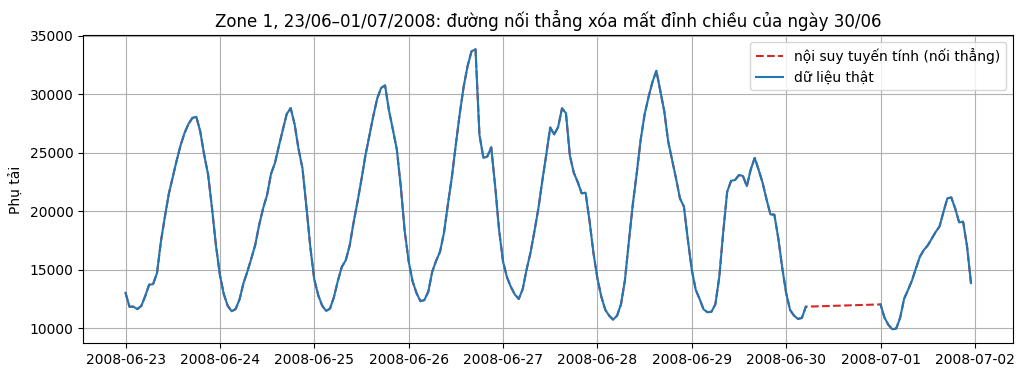

In [17]:
# [M1] Nhìn tận mắt vì sao không nên nối thẳng: zone 1 quanh chỗ thiếu
z1 = long[long["zone_id"] == 1].set_index("datetime")["load"]
window = z1["2008-06-23":"2008-07-01"]

plt.plot(window.interpolate(), linestyle="--", color="tab:red", label="nội suy tuyến tính (nối thẳng)")
plt.plot(window, color="tab:blue", label="dữ liệu thật")
plt.title("Zone 1, 23/06–01/07/2008: đường nối thẳng xóa mất đỉnh chiều của ngày 30/06")
plt.ylabel("Phụ tải")
plt.legend()
plt.show()

In [18]:
long = long.sort_values(["zone_id", "datetime"]).reset_index(drop=True)

# [M2] Đánh dấu TRƯỚC khi lấp (lấp xong thì không còn biết ô nào từng thiếu)
long["is_imputed"] = long["load"].isna()

# [M1] Giá trị cùng giờ tuần trước, tính RIÊNG trong từng zone
#      (groupby trước shift để dòng đầu mỗi zone không lấy nhầm dữ liệu zone khác;
#       shift(168) = lùi 1 tuần là đúng nhờ trục thời gian liên tục đã kiểm tra ở mục 5)
lag168 = long.groupby("zone_id")["load"].shift(168)
long["load"] = long["load"].fillna(lag168)

print("Giá trị còn thiếu      :", long["load"].isna().sum())
print("Số giờ được đánh dấu   :", long["is_imputed"].sum())
assert long["load"].isna().sum() == 0 and long["is_imputed"].sum() == 360

Giá trị còn thiếu      : 0
Số giờ được đánh dấu   : 360


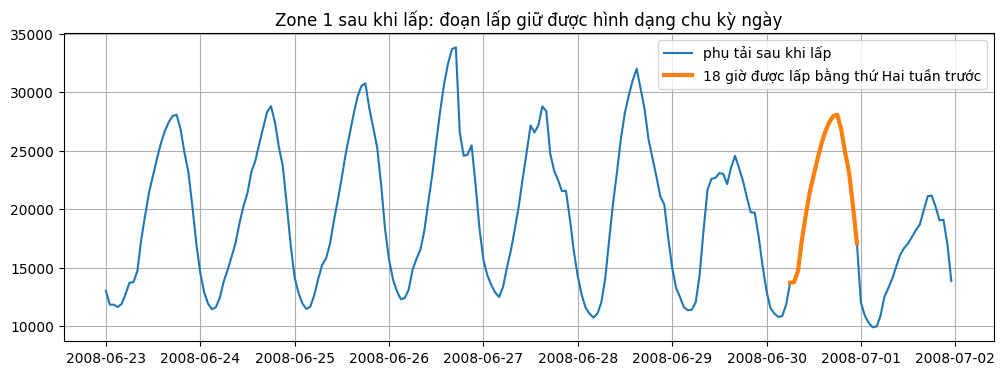

In [19]:
# Kiểm tra trực quan: đoạn được lấp có giống hình dạng các ngày thường xung quanh không
z1 = long[long["zone_id"] == 1].set_index("datetime")
window = z1.loc["2008-06-23":"2008-07-01"]

plt.plot(window["load"], color="tab:blue", label="phụ tải sau khi lấp")
plt.plot(window["load"].where(window["is_imputed"]), color="tab:orange", linewidth=3,
         label="18 giờ được lấp bằng thứ Hai tuần trước")
plt.title("Zone 1 sau khi lấp: đoạn lấp giữ được hình dạng chu kỳ ngày")
plt.legend()
plt.show()

In [20]:
# [M3] Cộng 20 zone theo từng giờ
system = (long.groupby("datetime")
              .agg(load=("load", "sum"),               # tổng phụ tải hệ thống
                   n_zones=("load", "count"),          # số zone có số liệu ở giờ đó
                   is_imputed=("is_imputed", "any"))   # True nếu có BẤT KỲ zone nào được lấp
              .reset_index())

print("system:", system.shape)
print(system["n_zones"].value_counts())
# pandas BỎ QUA NaN khi cộng: nếu một giờ thiếu zone, tổng sẽ thấp hơn thật mà không báo lỗi.
# Vì vậy phải kiểm tra giờ nào cũng đủ 20 zone.
assert (system["n_zones"] == 20).all()
assert len(system) == n_days * 24

system: (39600, 4)
n_zones
20    39600
Name: count, dtype: int64


In [21]:
# [M4] Kiểm chứng chuỗi tổng tự tạo bằng zone 21 (63 ngày x 24 giờ có trong file solution)
z21 = sol[sol["zone_id"] == 21].melt(id_vars=KEYS, value_vars=HOUR_COLS,
                                     var_name="hour", value_name="load_z21")
z21["hour"] = z21["hour"].str[1:].astype(int)
z21["datetime"] = (pd.to_datetime(z21[["year", "month", "day"]])
                   + pd.to_timedelta(z21["hour"] - 1, unit="h"))   # cùng quy ước nhãn đầu khoảng

check = system.merge(z21[["datetime", "load_z21"]], on="datetime")
print("Số giờ so sánh   :", len(check))
print("Chênh lệch lớn nhất:", (check["load"] - check["load_z21"]).abs().max())
assert len(check) == 63 * 24 and (check["load"] == check["load_z21"]).all()

Số giờ so sánh   : 1512
Chênh lệch lớn nhất: 0.0


In [22]:
# [M5] Lưu kết quả
long.to_parquet(PROCESSED_DIR / "load_zones.parquet", index=False)
system[["datetime", "load", "is_imputed"]].to_parquet(PROCESSED_DIR / "load_system.parquet", index=False)

# Đọc lại để chắc kiểu dữ liệu còn nguyên (đặc biệt cột datetime)
check_read = pd.read_parquet(PROCESSED_DIR / "load_system.parquet")
print(check_read.dtypes)
check_read.head()

datetime      datetime64[ns]
load                 float64
is_imputed              bool
dtype: object


,datetime,load,is_imputed
0,2004-01-01 00:00:00,1397668.0,False
1,2004-01-01 01:00:00,1351507.0,False
2,2004-01-01 02:00:00,1315742.0,False
3,2004-01-01 03:00:00,1308023.0,False
4,2004-01-01 04:00:00,1344117.0,False


### Nhận xét

- 30/06/2008 là **thứ Hai**, 29/06 là Chủ nhật, nên lấp bằng lag 168 (thứ Hai tuần trước) hợp lý hơn lag 24.
- Hình vẽ cho thấy nội suy tuyến tính nối thẳng qua cả buổi chiều, mất hẳn đỉnh phụ tải của ngày 30/06; cách lấp theo tuần trước giữ được hình dạng chu kỳ ngày.
- Sau khi lấp: **0** giá trị thiếu, **360** giờ-zone được đánh dấu `is_imputed` (tương ứng **18** giờ của chuỗi tổng).
- Chuỗi tổng có **39 600 giờ** (1 650 ngày × 24), giờ nào cũng đủ 20 zone, và **khớp tuyệt đối** với zone 21 trên 1 512 giờ của file solution.

## Tổng kết notebook 01

| Mục | Kết quả |
|---|---|
| 2.2 | Đọc đúng 33 000 × 28, số phụ tải là số thực |
| 2.3 | 9 tuần bị xóa (8 backcast + 1 dự báo) + 18 giờ mất hẳn ngày 30/06/2008 |
| 2.4 | Zone 21 = tổng 20 zone; bỏ `id`, `weight`; ghép chính xác và an toàn |
| 2.5 | Bảng dài 792 000 dòng, nhãn đầu khoảng, trục thời gian liên tục |
| 2.6 | Lấp 18 giờ bằng lag 168 có đánh dấu; chuỗi tổng 39 600 giờ khớp zone 21 |

**File đầu ra** (trong `data/processed/`, không đẩy lên GitHub):
- `load_zones.parquet`: 20 zone, cột `zone_id, datetime, load, is_imputed`
- `load_system.parquet`: chuỗi tổng, cột `datetime, load, is_imputed`

**Tiếp theo:** notebook 02 xử lý nhiệt độ, ngày lễ và ghép thành bảng tổng.